# House Price Prediction Model
Predict the selling price of a house (MEDV, in $1000s) from features like rooms, crime rate, age of the property and location.

Dataset: `HousingData.csv` (Boston Housing, with missing values).

In [ ]:
# House Price Prediction Model

## 1. Libraries

In [ ]:
# Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load the data

In [ ]:
# Loading
data = pd.read_csv("HousingData.csv")
print(data.head())

      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD  TAX  PTRATIO  \
0  0.00632  18.0   2.31   0.0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07   0.0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07   0.0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18   0.0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18   0.0  0.458  7.147  54.2  6.0622    3  222     18.7   

        B  LSTAT  MEDV  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.63   2.94  33.4  
4  396.90    NaN  36.2  


## 3. Explore the data

In [ ]:
# data exploring
data.info()
print("\n")
print(data.describe())

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     486 non-null    float64
 1   ZN       486 non-null    float64
 2   INDUS    486 non-null    float64
 3   CHAS     486 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      486 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    486 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


             CRIM          ZN       INDUS        CHAS         NOX          RM  \
count  486.000000  486.000000  486.000000  486.000000  506.000000  506.000000   
mean     3.611874   11.211934   11.083992    0.069959    0.554695    6.284634   
s

## 4. Clean the data

In [ ]:
# data cleaning
print("Missing values:\n", data.isnull().sum())
data = data.drop_duplicates()
# missing values are filled with the median later (inside the pipeline),
# so we do not lose any rows

Missing values:
 CRIM       20
ZN         20
INDUS      20
CHAS       20
NOX         0
RM          0
AGE        20
DIS         0
RAD         0
TAX         0
PTRATIO     0
B           0
LSTAT      20
MEDV        0
dtype: int64


## 5. Features and target

In [ ]:
# MEDV = median house price in $1000s
X = data.drop('MEDV', axis=1)
y = data['MEDV']

## 6. Correlation with price

In [ ]:
# quick look: how each feature is related to price
print("\nCorrelation with MEDV:")
print(data.corr()['MEDV'].sort_values(ascending=False))


Correlation with MEDV:
MEDV       1.000000
RM         0.695360
ZN         0.373136
B          0.333461
DIS        0.249929
CHAS       0.181391
RAD       -0.381626
CRIM      -0.391363
AGE       -0.394656
NOX       -0.427321
TAX       -0.468536
INDUS     -0.481772
PTRATIO   -0.507787
LSTAT     -0.735822
Name: MEDV, dtype: float64


## 7. Train / test split

In [ ]:
# model train and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 8. Evaluation helper and pipeline

In [ ]:
# helper to print the evaluation of a model
def evaluate(name, model):
    pred = model.predict(X_test)
    print(f"\n{name}:")
    print("MAE: ", round(mean_absolute_error(y_test, pred), 4))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 4))
    print("R2:  ", round(r2_score(y_test, pred), 4))
    return r2_score(y_test, pred)

In [ ]:
# each pipeline = fill missing values -> normalize -> model
def make_pipeline(model):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', model)
    ])

## 9. Train the models

In [ ]:
# Model 1: Linear Regression
model_lr = make_pipeline(LinearRegression())
model_lr.fit(X_train, y_train)
r2_lr = evaluate("Linear Regression", model_lr)


Linear Regression:
MAE:  3.1476
RMSE: 4.9983
R2:   0.6593


In [ ]:
# Model 2: Decision Tree
model_dt = make_pipeline(DecisionTreeRegressor(random_state=42))
model_dt.fit(X_train, y_train)
r2_dt = evaluate("Decision Tree", model_dt)


Decision Tree:
MAE:  3.1529
RMSE: 5.1122
R2:   0.6436


In [ ]:
# Model 3: Random Forest
model_rf = make_pipeline(RandomForestRegressor(random_state=42))
model_rf.fit(X_train, y_train)
r2_rf = evaluate("Random Forest", model_rf)


Random Forest:
MAE:  2.0502
RMSE: 2.8571
R2:   0.8887


In [ ]:
# Model 4: Gradient Boosting (same idea as XGBoost)
model_gb = make_pipeline(GradientBoostingRegressor(random_state=42))
model_gb.fit(X_train, y_train)
r2_gb = evaluate("Gradient Boosting", model_gb)


Gradient Boosting:
MAE:  1.9187
RMSE: 2.7024
R2:   0.9004


## 10. Hyperparameter tuning

In [ ]:
# hyperparameter tuning
print("\nTuning Random Forest...")
rf_params = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}
grid_rf = GridSearchCV(make_pipeline(RandomForestRegressor(random_state=42)),
                       rf_params, cv=5, scoring='r2', n_jobs=-1)
grid_rf.fit(X_train, y_train)
print("Best parameters:", grid_rf.best_params_)
print("Best CV R2:", round(grid_rf.best_score_, 4))
r2_rf_tuned = evaluate("Random Forest (tuned)", grid_rf.best_estimator_)


Tuning Random Forest...


Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best CV R2: 0.8068

Random Forest (tuned):
MAE:  2.0673
RMSE: 2.8941
R2:   0.8858


In [ ]:
print("\nTuning Gradient Boosting...")
gb_params = {
    'model__n_estimators': [100, 200, 300],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [2, 3, 4],
    'model__subsample': [0.8, 1.0]
}
grid_gb = GridSearchCV(make_pipeline(GradientBoostingRegressor(random_state=42)),
                       gb_params, cv=5, scoring='r2', n_jobs=-1)
grid_gb.fit(X_train, y_train)
print("Best parameters:", grid_gb.best_params_)
print("Best CV R2:", round(grid_gb.best_score_, 4))
r2_gb_tuned = evaluate("Gradient Boosting (tuned)", grid_gb.best_estimator_)


Tuning Gradient Boosting...


Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 300, 'model__subsample': 0.8}
Best CV R2: 0.8491

Gradient Boosting (tuned):
MAE:  1.9609
RMSE: 2.6887
R2:   0.9014


## 11. Compare models

In [ ]:
# compare all models and pick the best one
results = {
    'Linear Regression': (r2_lr, model_lr),
    'Decision Tree': (r2_dt, model_dt),
    'Random Forest': (r2_rf, model_rf),
    'Gradient Boosting': (r2_gb, model_gb),
    'Random Forest (tuned)': (r2_rf_tuned, grid_rf.best_estimator_),
    'Gradient Boosting (tuned)': (r2_gb_tuned, grid_gb.best_estimator_),
}
print("\nModel comparison (R2 on test set):")
for name, (score, _) in sorted(results.items(), key=lambda item: item[1][0], reverse=True):
    print(f"{name}: {round(score, 4)}")

best_name = max(results, key=lambda k: results[k][0])
best_model = results[best_name][1]
print("\nBest model:", best_name)


Model comparison (R2 on test set):
Gradient Boosting (tuned): 0.9014
Gradient Boosting: 0.9004
Random Forest: 0.8887
Random Forest (tuned): 0.8858
Linear Regression: 0.6593
Decision Tree: 0.6436

Best model: Gradient Boosting (tuned)


## 12. Plots

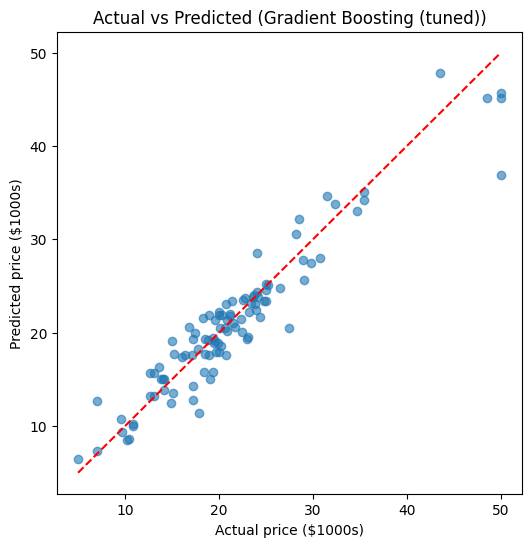

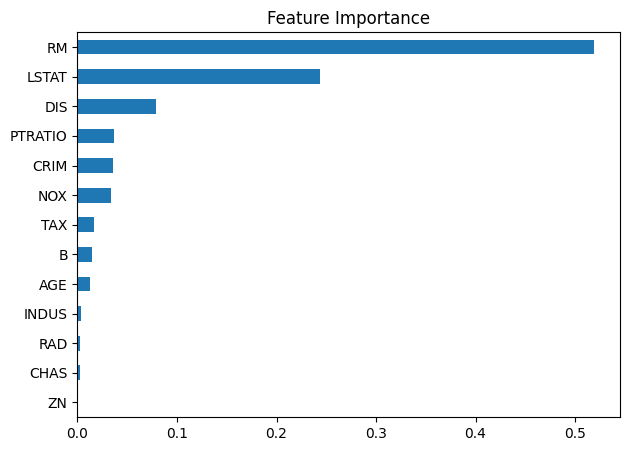


Feature importance:
RM         0.5192
LSTAT      0.2436
DIS        0.0793
PTRATIO    0.0366
CRIM       0.0353
NOX        0.0334
TAX        0.0162
B          0.0144
AGE        0.0126
INDUS      0.0037
RAD        0.0028
CHAS       0.0026
ZN         0.0004
dtype: float64


In [ ]:
# plots: actual vs predicted, and feature importance
pred_best = best_model.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_best, alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.xlabel("Actual price ($1000s)")
plt.ylabel("Predicted price ($1000s)")
plt.title(f"Actual vs Predicted ({best_name})")
plt.savefig("actual_vs_predicted.png", dpi=120, bbox_inches='tight')
plt.show()

final_model = best_model.named_steps['model']
if hasattr(final_model, 'feature_importances_'):
    importance = pd.Series(final_model.feature_importances_, index=X.columns).sort_values()
    plt.figure(figsize=(7, 5))
    importance.plot(kind='barh')
    plt.title("Feature Importance")
    plt.savefig("feature_importance.png", dpi=120, bbox_inches='tight')
    plt.show()
    print("\nFeature importance:")
    print(importance.sort_values(ascending=False).round(4))

## 13. Predict a new house

In [ ]:
# Command-line interface
# Only the main features are asked. The rest use the median of the dataset.
main_features = {
    'RM': 'Average number of rooms per house',
    'LSTAT': '% of lower status population in the area',
    'PTRATIO': 'Pupil-teacher ratio in the area',
    'CRIM': 'Crime rate per capita',
    'AGE': '% of houses built before 1940 (age of property)',
    'DIS': 'Distance to employment centres',
}

def predict_price(user_values):
    row = X.median().to_dict()      # start with median for every feature
    row.update(user_values)         # replace with what the user entered
    row_df = pd.DataFrame([row])[X.columns]
    return best_model.predict(row_df)[0]

In [ ]:
# example prediction
example = {'RM': 6.5, 'LSTAT': 10, 'PTRATIO': 18, 'CRIM': 0.3, 'AGE': 60, 'DIS': 4}
print("\nExample house:", example)
print(f"Predicted price: ${predict_price(example) * 1000:,.0f}")


Example house: {'RM': 6.5, 'LSTAT': 10, 'PTRATIO': 18, 'CRIM': 0.3, 'AGE': 60, 'DIS': 4}
Predicted price: $22,473


## 14. Try your own house
Change the numbers below and run the cell.

In [ ]:
my_house = {'RM': 7, 'LSTAT': 6, 'PTRATIO': 16, 'CRIM': 0.1, 'AGE': 40, 'DIS': 5}
print(f"Predicted price: ${predict_price(my_house) * 1000:,.0f}")

Predicted price: $30,269
